# Titanic: Who Survived and Why?

**Stack:** Python, pandas, seaborn, scikit-learn

> **Project origin.** Originally completed as a weekly assignment in an Introduction to Machine Learning course (KBTU). This version is restructured as a standalone case study and extended with the additional analysis listed below.

**What this version adds**

- a data-quality decision about **duplicate rows** (they are not real duplicates here, so they are kept)
- smarter age imputation (median by class and sex instead of one global median)
- new features: family size, age group, log-scaled fare
- survival analysis by sex, class, age and family, plus a baseline logistic regression with odds ratios

## Goal

Understand which passenger characteristics were associated with survival on the Titanic, and check how well a simple
model can predict survival.

**Data:** the `titanic` dataset (891 passengers) from seaborn.

In [99]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

df = sns.load_dataset("titanic")
print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.283,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.100,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.050,S,Third,man,True,NaN,Southampton,no,True


## 1. Data quality

In [102]:
missing = df.isna().sum()
display((missing[missing > 0] / len(df) * 100).round(1).to_frame("% missing"))

n_dup = int(df.duplicated().sum())
print(f"Rows identical across all columns: {n_dup}")
print(f"Survival rate, all rows:            {df['survived'].mean():.1%}")
print(f"Survival rate, duplicates dropped:  {df.drop_duplicates()['survived'].mean():.1%}")

,% missing
age,19.9
embarked,0.2
deck,77.2
embark_town,0.2


Rows identical across all columns: 107
Survival rate, all rows:            38.4%
Survival rate, duplicates dropped:  41.2%


**Decisions**

- `deck` is missing for most passengers, so it is dropped.
- `alive` and `embark_town` repeat `survived` and `embarked`, so they are dropped.
- The dataset has **no passenger ID or name**, so rows that are identical across all columns are most likely *different
  passengers* with the same attributes (for example, third-class men travelling alone). Dropping them would delete real
  people and shift the survival rate, so I keep them.
- Missing ages are filled with the median age of passengers of the same class and sex, which is more realistic than one
  global median.

In [105]:
data = df.drop(columns=["deck", "alive", "embark_town"]).copy()
data["age"] = data["age"].fillna(data.groupby(["pclass", "sex"])["age"].transform("median"))
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])

data["family_size"] = data["sibsp"] + data["parch"] + 1
data["age_group"] = pd.cut(data["age"], bins=[0, 12, 18, 35, 60, 100],
                           labels=["Child (12 or younger)", "Teen (13-18)", "Adult (19-35)",
                                   "Middle-aged (36-60)", "Senior (over 60)"])
data["fare_log"] = np.log1p(data["fare"])

print("Missing values left:", int(data.isna().sum().sum()))
data.head()

Missing values left: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone,family_size,age_group,fare_log
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,False,2,Adult (19-35),2.110
1,1,1,female,38.0,1,0,71.283,C,First,woman,False,False,2,Middle-aged (36-60),4.281
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,True,1,Adult (19-35),2.189
3,1,1,female,35.0,1,0,53.100,S,First,woman,False,False,2,Adult (19-35),3.991
4,0,3,male,35.0,0,0,8.050,S,Third,man,True,True,1,Adult (19-35),2.203


## 2. Who survived?

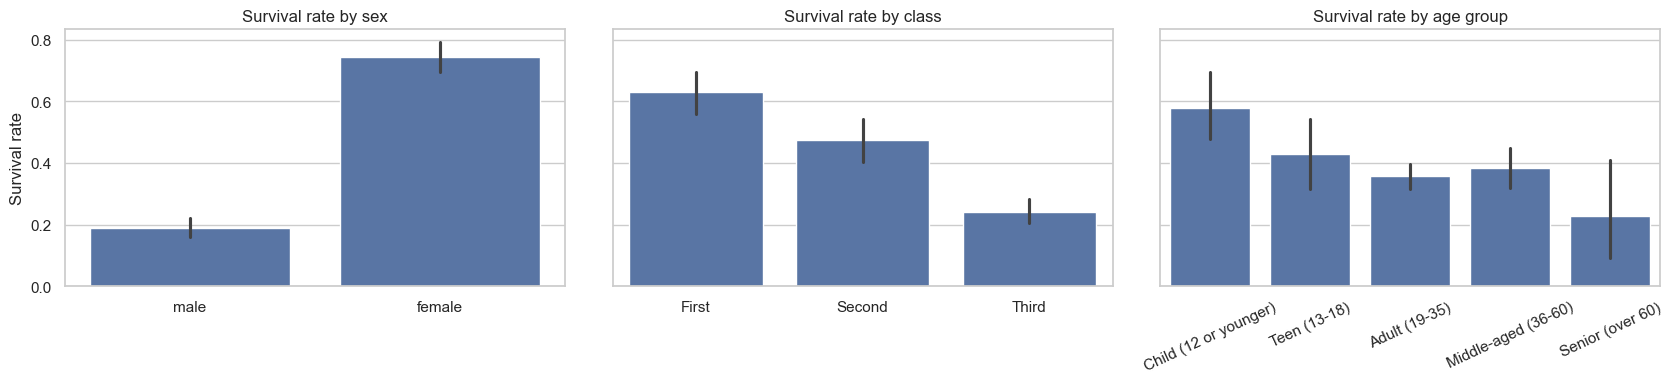

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
sns.barplot(data=data, x="sex", y="survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")
sns.barplot(data=data, x="class", y="survived", order=["First", "Second", "Third"], ax=axes[1])
axes[1].set_title("Survival rate by class")
sns.barplot(data=data, x="age_group", y="survived", ax=axes[2])
axes[2].set_title("Survival rate by age group")
axes[2].tick_params(axis="x", rotation=25)
for ax in axes:
    ax.set_xlabel("")
axes[0].set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

C:\Users\galye\AppData\Local\Temp\ipykernel_17736\2182842522.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = pd.pivot_table(data, values="survived", index="sex", columns="class", aggfunc="mean")


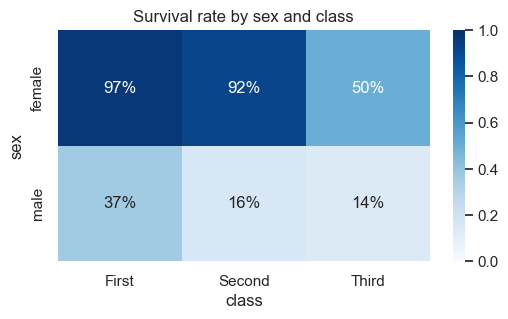

In [109]:
pivot = pd.pivot_table(data, values="survived", index="sex", columns="class", aggfunc="mean")
pivot = pivot[["First", "Second", "Third"]]
plt.figure(figsize=(6, 3))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.title("Survival rate by sex and class")
plt.show()

In [110]:
fam = data.groupby("family_size").agg(passengers=("survived", "size"), survival_rate=("survived", "mean"))
display(fam)

data.groupby("embarked")["survived"].agg(passengers="size", survival_rate="mean")

,passengers,survival_rate
family_size,,
1,537,0.304
2,161,0.553
3,102,0.578
4,29,0.724
5,15,0.200
6,22,0.136
7,12,0.333
8,6,0.000
11,7,0.000


,passengers,survival_rate
embarked,,
C,168,0.554
Q,77,0.390
S,646,0.339


## 3. Fare

Fares are heavily right-skewed (a few passengers paid more than 500). Rather than clipping the extreme values, I use a
log transform, which keeps every passenger and makes the feature better behaved.

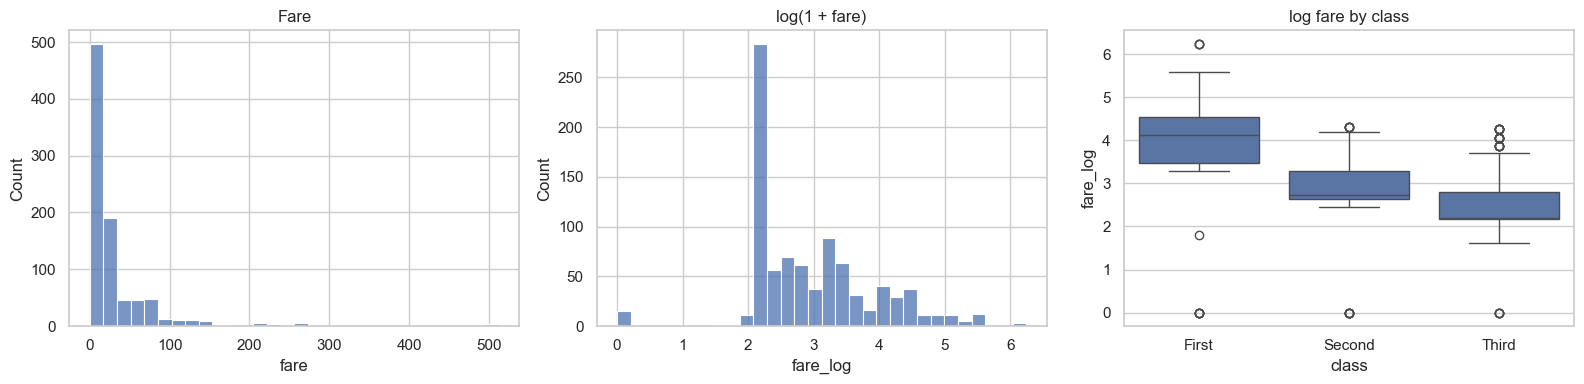

In [112]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data["fare"], bins=30, ax=axes[0])
axes[0].set_title("Fare")
sns.histplot(data["fare_log"], bins=30, ax=axes[1])
axes[1].set_title("log(1 + fare)")
sns.boxplot(data=data, x="class", y="fare_log", order=["First", "Second", "Third"], ax=axes[2])
axes[2].set_title("log fare by class")
plt.tight_layout()
plt.show()

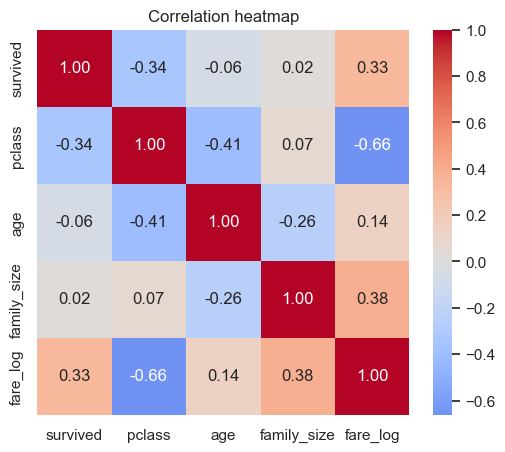

In [113]:
num_for_corr = ["survived", "pclass", "age", "family_size", "fare_log"]
corr = data[num_for_corr].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

## 4. A baseline survival model

A logistic regression on class, sex, age, family size, log fare and port of embarkation. It is evaluated with 5-fold
stratified cross-validation and compared with a baseline that always predicts the most common outcome.

In [116]:
features = ["pclass", "age", "family_size", "fare_log", "sex", "embarked"]
X, y = data[features], data["survived"]

pre = ColumnTransformer([
    ("num", StandardScaler(), ["pclass", "age", "family_size", "fare_log"]),
    ("cat", OneHotEncoder(), ["sex", "embarked"]),
])
logit = Pipeline([("pre", pre), ("model", LogisticRegression(max_iter=1000))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_base = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv, scoring="accuracy")
acc = cross_val_score(logit, X, y, cv=cv, scoring="accuracy")
auc = cross_val_score(logit, X, y, cv=cv, scoring="roc_auc")

print(f"Baseline accuracy: {acc_base.mean():.3f}")
print(f"Logistic regression accuracy: {acc.mean():.3f} (std {acc.std():.3f})")
print(f"Logistic regression ROC AUC:  {auc.mean():.3f}")

Baseline accuracy: 0.616
Logistic regression accuracy: 0.800 (std 0.012)
Logistic regression ROC AUC:  0.856


In [117]:
logit.fit(X, y)
names = logit.named_steps["pre"].get_feature_names_out()
odds = pd.Series(np.exp(logit.named_steps["model"].coef_[0]), index=names).sort_values(ascending=False)
odds.rename("odds ratio").to_frame()

,odds ratio
cat__sex_female,3.614
num__fare_log,1.397
cat__embarked_C,1.125
cat__embarked_Q,1.015
cat__embarked_S,0.815
num__family_size,0.619
num__age,0.573
num__pclass,0.444
cat__sex_male,0.258


Odds ratios above 1 increase the odds of survival, below 1 decrease them. For numeric features (`num__`) the ratio is
per one standard deviation; for categories (`cat__`) it is relative to not being in that category.

## 5. Key findings

In [122]:
sex_rate = data.groupby("sex")["survived"].mean()
cls_rate = data.groupby("pclass")["survived"].mean()
child_rate = data.loc[data["age"] <= 12, "survived"].mean()
corr_s = corr["survived"].drop("survived").sort_values()

findings = [
    f"- **Overall survival:** {data['survived'].mean():.1%} of passengers.",
    f"- **Sex:** {sex_rate.loc['female']:.0%} of women survived vs {sex_rate.loc['male']:.0%} of men.",
    f"- **Class:** survival fell from {cls_rate.loc[1]:.0%} in first class to {cls_rate.loc[3]:.0%} in third class.",
    f"- **Children (12 or younger):** {child_rate:.0%} survived.",
    f"- **Strongest linear correlates of survival:** {corr_s.index[-1]} (positive, r = {corr_s.iloc[-1]:.2f}) and "
    f"{corr_s.index[0]} (negative, r = {corr_s.iloc[0]:.2f}).",
    f"- **Baseline model:** logistic regression reaches {acc.mean():.1%} cross-validated accuracy "
    f"(ROC AUC {auc.mean():.2f}) vs {acc_base.mean():.1%} for always predicting the most common outcome.",
]
display(Markdown("\n".join(findings)))

- **Overall survival:** 38.4% of passengers.
- **Sex:** 74% of women survived vs 19% of men.
- **Class:** survival fell from 63% in first class to 24% in third class.
- **Children (12 or younger):** 58% survived.
- **Strongest linear correlates of survival:** fare_log (positive, r = 0.33) and pclass (negative, r = -0.34).
- **Baseline model:** logistic regression reaches 80.0% cross-validated accuracy (ROC AUC 0.86) vs 61.6% for always predicting the most common outcome.

## 6. Limitations

- Observational historical data: associations (for example, between fare and survival) partly reflect class, cabin location and access to lifeboats, not a direct effect of price.
- Age was missing for about 20% of passengers and was imputed, which adds uncertainty to age-related findings.
- The model is a simple baseline; no hyperparameter tuning or more complex models were tried.